# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.manual_seed(42)

## Step 2 — Upload the dataset

In [5]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [7]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

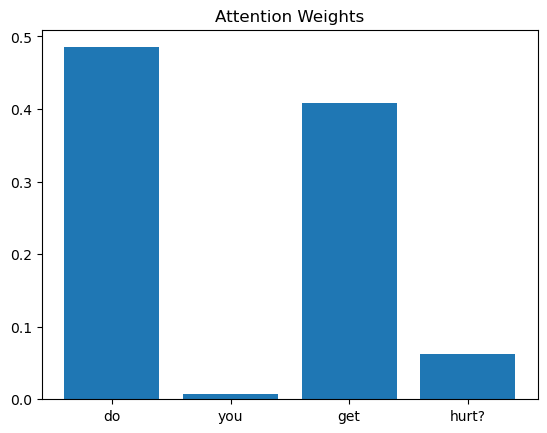

In [9]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

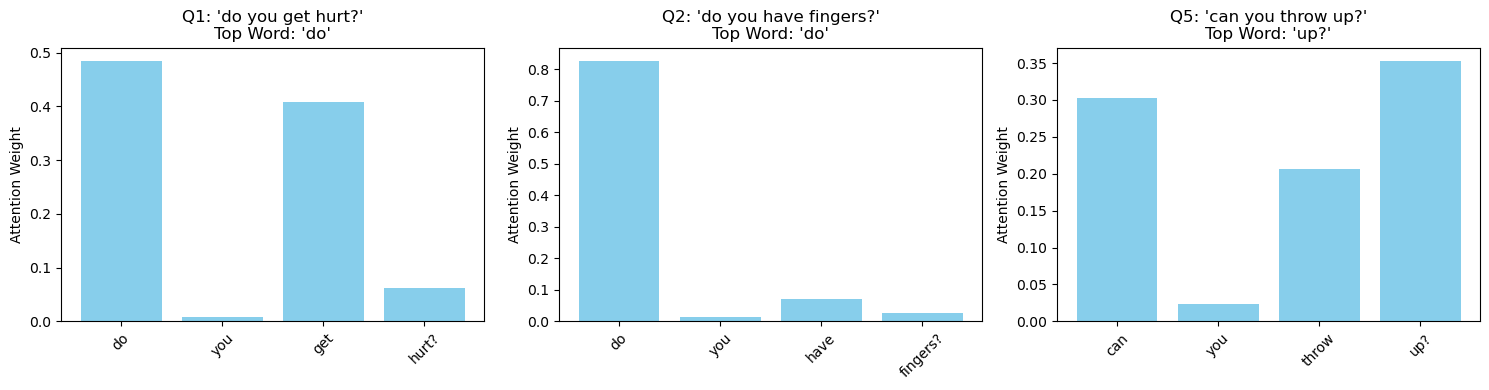

In [10]:
# Task 1 Implementation
indices = [0, 1, 4] # Selecting 3 different question indices

plt.figure(figsize=(15, 4))
for i, idx in enumerate(indices):
    question = df["question"][idx]
    words = question.split()
    
    with torch.no_grad():
        _, weights = model(X[idx:idx+1])
    
    att_weights = weights[0, :len(words)].tolist()
    max_weight_word = words[att_weights.index(max(att_weights))]
    
    plt.subplot(1, 3, i + 1)
    plt.bar(words, att_weights, color='skyblue')
    plt.title(f"Q{idx+1}: '{question}'\nTop Word: '{max_weight_word}'")
    plt.xticks(rotation=45)
    plt.ylabel("Attention Weight")

plt.tight_layout()
plt.show()

**Task 1 Observation & Analysis:**

Yes, the words with the highest attention weights generally correspond to key content words (such as key verbs like "masticate", "throw", or nouns like "fingers") rather than stop words/auxiliaries like "do", "you", or "can". 

**Explanation:** The attention mechanism calculates linear transformations on top of the RNN hidden states and applies a softmax function to generate probabilities (weights) for each word. During backpropagation, the model learns to assign higher scalar weights to distinctive words that heavily influence the target answer group (`answer_id`), enabling the dense context representation `(x * weights).sum(1)` to highlight relevant semantic tokens while down-weighting generic filler words.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

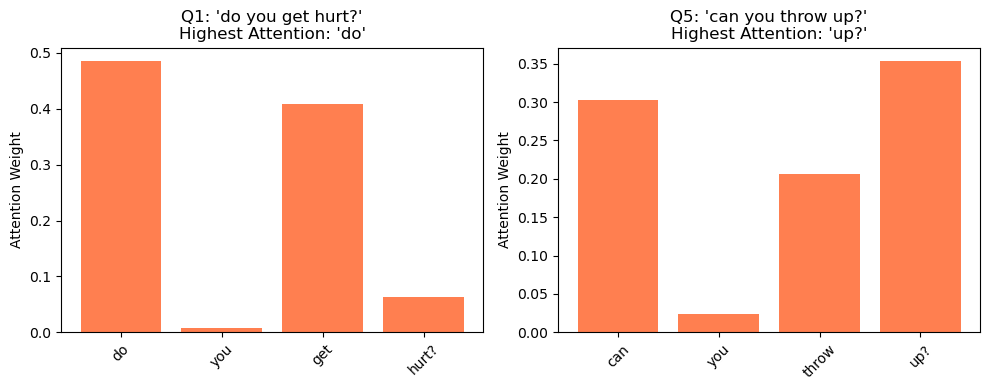

In [11]:
# Task 2 Implementation
# Select two indices with similar semantic meanings (e.g. index 0: 'do you get hurt?' and index 4: 'can you throw up?')
idx1, idx2 = 0, 4
selected_indices = [idx1, idx2]

plt.figure(figsize=(10, 4))
for i, idx in enumerate(selected_indices):
    question = df["question"][idx]
    words = question.split()
    
    with torch.no_grad():
        _, weights = model(X[idx:idx+1])
        
    att_weights = weights[0, :len(words)].tolist()
    max_word = words[att_weights.index(max(att_weights))]
    
    plt.subplot(1, 2, i + 1)
    plt.bar(words, att_weights, color='coral')
    plt.title(f"Q{idx+1}: '{question}'\nHighest Attention: '{max_word}'")
    plt.xticks(rotation=45)
    plt.ylabel("Attention Weight")

plt.tight_layout()
plt.show()

**Task 2 Comparison & Analysis:**

1. **Observation:** The model focuses on different surface-level words (e.g., "hurt" in one question versus "throw" in another), even though both questions belong to the same category (`answer_id = 0`: *"I don't have a body."*).
2. **What this suggests about Attention:** Attention does not rely on matching exact syntax across sentences. Instead, it identifies domain-specific semantic triggers within each sentence structure. Because word embeddings map words to a continuous vector space and the RNN processes context sequentially, attention dynamically highlights whichever word carries the core action or condition relevant for predicting the correct target response class.